<a href="https://colab.research.google.com/github/nowrin-12/rl-5g-scheduler/blob/main/phase1_toower.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)

In [ ]:
N_USERS = 10
CELL_RADIUS = 500
MIN_DIST = 50
BANDWIDTH = 10e6
TX_POWER_DBM = 30
NOISE_DBM = -174 + 10*np.log10(BANDWIDTH) + 9
DT = 0.01
SPEED = 10
PACKET_BITS = 12000
ARRIVAL_LAMBDA = 3

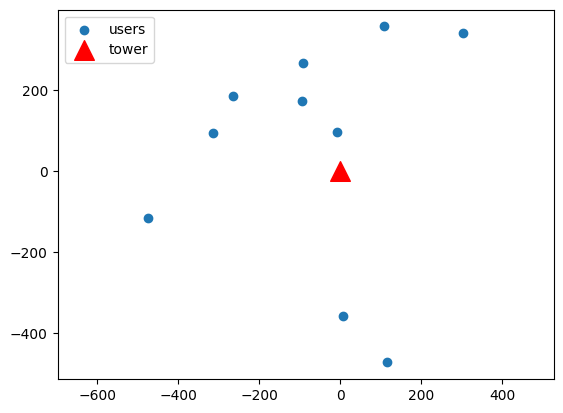

In [ ]:
r = np.sqrt(rng.uniform(MIN_DIST**2, CELL_RADIUS**2, N_USERS))
theta = rng.uniform(0, 2*np.pi, N_USERS)
pos = np.stack([r*np.cos(theta), r*np.sin(theta)], axis=1)

plt.scatter(pos[:, 0], pos[:, 1], label="users")
plt.scatter(0, 0, marker="^", s=200, color="red", label="tower")
plt.axis("equal"); plt.legend(); plt.show()

In [ ]:
 def path_loss_db(pos):
    dist_km = np.maximum(np.linalg.norm(pos, axis=1), 1.0) / 1000
    return 128.1 + 37.6*np.log10(dist_km)

print(np.round(path_loss_db(pos), 1))

[111.4 116.4 101.4 116.4 107.4 109.9 115.3 109.6 112.   89.9]


In [ ]:
def compute_rates(pos):
    fading_db = 10*np.log10(rng.exponential(1.0, len(pos)))
    rx_dbm = TX_POWER_DBM - path_loss_db(pos) + fading_db
    snr_db = np.clip(rx_dbm - NOISE_DBM, -10, 30)
    snr = 10**(snr_db/10)
    return BANDWIDTH*np.log2(1 + snr)

for _ in range(3):
    print(np.round(compute_rates(pos)/1e6, 1))

[59.5 31.9 76.8 44.5 68.7 52.8 20.4 56.6 20.6 99.7]
[26.8 42.5 87.6 17.4 66.9 13.5 37.9 54.1 11.3 99.7]
[64.5 27.7 70.2 24.4 60.8 41.9 18.2 51.9 49.1 99.7]


In [ ]:
heading = rng.uniform(0, 2*np.pi, N_USERS)

def move(pos, heading):
    heading = heading + rng.normal(0, 0.3, len(pos))
    pos = pos + SPEED*DT*np.stack([np.cos(heading), np.sin(heading)], axis=1)
    dist = np.linalg.norm(pos, axis=1)
    far, near = dist > CELL_RADIUS, dist < MIN_DIST
    pos[far] *= (CELL_RADIUS/dist[far])[:, None]
    pos[near] *= (MIN_DIST/dist[near])[:, None]
    heading[far | near] += np.pi
    return pos, heading

In [ ]:
def arrive(buffer):
    return buffer + rng.poisson(ARRIVAL_LAMBDA, len(buffer))*PACKET_BITS

def serve(buffer, rates, user):
    served = min(buffer[user], rates[user]*DT)
    buffer[user] -= served
    return buffer, served

In [ ]:
class Tower:
    def __init__(self, n_users=10, seed=0):
        self.n_users = n_users
        self.rng = np.random.default_rng(seed)
        self.avg_window = 100
        self.reset()

    def reset(self):
        r = np.sqrt(self.rng.uniform(MIN_DIST**2, CELL_RADIUS**2, self.n_users))
        theta = self.rng.uniform(0, 2*np.pi, self.n_users)
        self.pos = np.stack([r*np.cos(theta), r*np.sin(theta)], axis=1)
        self.heading = self.rng.uniform(0, 2*np.pi, self.n_users)
        self.buffer = np.zeros(self.n_users)
        self.avg_tp = np.full(self.n_users, 1e5)
        self.t = 0
        self.rates = self._rates()
        return self.rates

    def _rates(self):
        dist_km = np.maximum(np.linalg.norm(self.pos, axis=1), 1.0)/1000
        pl = 128.1 + 37.6*np.log10(dist_km)
        fading = 10*np.log10(self.rng.exponential(1.0, self.n_users))
        snr_db = np.clip(TX_POWER_DBM - pl + fading - NOISE_DBM, -10, 30)
        return BANDWIDTH*np.log2(1 + 10**(snr_db/10))

    def _move(self):
        self.heading += self.rng.normal(0, 0.3, self.n_users)
        self.pos += SPEED*DT*np.stack([np.cos(self.heading), np.sin(self.heading)], axis=1)
        dist = np.linalg.norm(self.pos, axis=1)
        far, near = dist > CELL_RADIUS, dist < MIN_DIST
        self.pos[far] *= (CELL_RADIUS/dist[far])[:, None]
        self.pos[near] *= (MIN_DIST/dist[near])[:, None]
        self.heading[far | near] += np.pi

    def step(self, user):
        served = min(self.buffer[user], self.rates[user]*DT)
        self.buffer[user] -= served
        served_rate = np.zeros(self.n_users)
        served_rate[user] = served/DT
        self.avg_tp = (1 - 1/self.avg_window)*self.avg_tp + (1/self.avg_window)*served_rate
        self.buffer += self.rng.poisson(ARRIVAL_LAMBDA, self.n_users)*PACKET_BITS
        self._move()
        self.rates = self._rates()
        self.t += 1
        return served

In [ ]:
tower = Tower(n_users=10, seed=1)
total_bits = 0
for step in range(500):
    total_bits += tower.step(step % tower.n_users)
print(total_bits/1e6, "Mbit delivered")

166.9683955372701 Mbit delivered
